# NLP Lab 6 — Syntax Parsing & Classical Machine Translation
**Faculty of Engineering — Beirut Arab University** · *Solved lab notebook*

| Part | Topic | Lecture slides |
|---|---|---|
| 1 | Context-Free Grammars & parse trees | 3–8 |
| 2 | Chomsky Normal Form | 10 |
| 3 | Probabilistic CKY (Viterbi) | 11–17 |
| 4 | Transition-based dependency parsing | 18–31 |
| 5 | Statistical MT: noisy channel & phrase-based decoding | 32–45 |
| 6 | BLEU evaluation | 46–58 |
| 7 | Practice exercises (with hidden solutions) | — |
| 8 | Mini-project: ✈️ Flight Booking Assistant (Streamlit app) | all |

Everything is written **from scratch in plain Python** (no NLTK/spaCy) so you can see every step of the math from the slides.

> 💡 **How to use this notebook:** run the cells top to bottom (`Shift + Enter`). Each part ends with a ✅ check that reproduces the number from the slides.

In [1]:
import math
import itertools
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"nt": "#1f4e79", "t": "#c55a11", "ok": "#2e7d32", "bad": "#c62828", "gray": "#7f7f7f"}
print("Setup complete ✔")

Setup complete ✔


### Helper — drawing trees
A parse tree is stored as a nested tuple: `(label, child1, child2, ...)`; a leaf word is a plain string.
You don't need to modify this cell — just run it.

In [2]:
def draw_tree(tree, title="", ax=None, prob=None):
    # Layout: leaves spaced evenly on x, depth on y; each parent centred over its children.
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    pos, edges, leaf_x = {}, [], [0]
    def depth(t):
        return 0 if isinstance(t, str) else 1 + max(depth(c) for c in t[1:])
    D = depth(tree)
    def place(t, d, path):
        if isinstance(t, str):                      # terminal (word)
            x = leaf_x[0]; leaf_x[0] += 1
            pos[path] = (x, -D, t, True)
            return x
        xs = [place(c, d + 1, path + (i,)) for i, c in enumerate(t[1:])]
        x = sum(xs) / len(xs)
        pos[path] = (x, -d, t[0], False)
        for i in range(len(xs)):
            edges.append((path, path + (i,)))
        return x
    place(tree, 0, ())
    for a, b in edges:
        ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color="#bbbbbb", zorder=1)
    for x, y, lab, leaf in pos.values():
        ax.text(x, y, lab, ha="center", va="center", zorder=2,
                fontsize=12 if leaf else 11, fontweight="normal" if leaf else "bold",
                color="white" if not leaf else COLORS["t"],
                bbox=dict(boxstyle="round,pad=0.35",
                          fc=COLORS["nt"] if not leaf else "#fbe5d6",
                          ec="none"))
    ax.set_xlim(-0.8, leaf_x[0] - 0.2); ax.set_ylim(-D - 0.6, 0.6); ax.axis("off")
    t = title + (f"   (P = {prob:.3f})" if prob is not None else "")
    ax.set_title(t, fontsize=12)
    return ax

---
## Part 1 — Context-Free Grammars: $G = (V, \Sigma, R, S)$

| Symbol | Meaning | Example |
|---|---|---|
| $V$ | **Non-terminals** — structural tags, never appear in the sentence | `S, NP, VP, Det, N, V` |
| $\Sigma$ | **Terminals** — the actual words (leaves of the tree) | `the, cat, sleeps` |
| $R$ | **Rules** $A \rightarrow \alpha$, with $A \in V$ and $\alpha \in (V \cup \Sigma)^*$ | `S → NP VP` |
| $S$ | **Start symbol** — every derivation begins here | `S` |

> 💡 **Hint:** the *disjoint constraint* $V \cap \Sigma = \emptyset$ means a symbol can't be both a tag and a word. We check it in code below.

In [3]:
# Grammar from slide 8: "The cat sleeps"
V     = {"S", "NP", "VP", "Det", "N", "V"}
Sigma = {"the", "cat", "sleeps"}
S     = "S"
R = {
    "S":   [("NP", "VP")],
    "NP":  [("Det", "N")],
    "VP":  [("V",)],
    "Det": [("the",)],
    "N":   [("cat",)],
    "V":   [("sleeps",)],
}

# --- Sanity checks on the 4-tuple ---
assert V.isdisjoint(Sigma), "V and Σ must be disjoint!"
assert S in V, "Start symbol must be a non-terminal"
for lhs, rhss in R.items():
    assert lhs in V, f"LHS {lhs} must be a single non-terminal"
    for rhs in rhss:
        assert all(sym in V | Sigma for sym in rhs), f"Unknown symbol in {lhs} -> {rhs}"
print("G = (V, Σ, R, S) is a valid CFG ✔")

G = (V, Σ, R, S) is a valid CFG ✔


### 1.1 The CFG "factory": a leftmost derivation
Start at `S`, repeatedly rewrite the **leftmost non-terminal** using a rule, until only terminals remain.

In [4]:
def leftmost_derivation(R, start, choose=lambda opts: opts[0]):
    sent = [start]
    steps = [" ".join(sent)]
    while any(s in R for s in sent):
        i = next(k for k, s in enumerate(sent) if s in R)      # leftmost non-terminal
        sent = sent[:i] + list(choose(R[sent[i]])) + sent[i+1:]
        steps.append(" ".join(sent))
    return steps

for k, s in enumerate(leftmost_derivation(R, "S")):
    print(f"{'' if k == 0 else '⇒ '}{s}")

S
⇒ NP VP
⇒ Det N VP
⇒ the N VP
⇒ the cat VP
⇒ the cat V
⇒ the cat sleeps


### 1.2 Visualising the parse tree (slide 8)

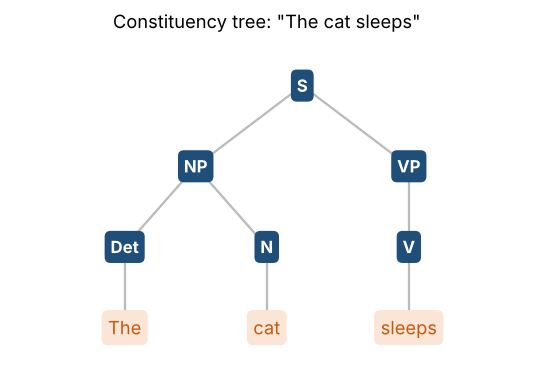

In [5]:
tree_cat = ("S", ("NP", ("Det", "The"), ("N", "cat")), ("VP", ("V", "sleeps")))
draw_tree(tree_cat, 'Constituency tree: "The cat sleeps"'); plt.show()

### 1.3 Recursion: finite rules → infinite sentences
The rule `NP → NP PP` (slide 6) lets a noun phrase contain another noun phrase. We generate random sentences to see it.

> 💡 **Hint:** we cap the depth, otherwise `NP → NP PP` could recurse forever.

In [6]:
import random
random.seed(7)

R_rec = {
    "S":  [("NP", "VP")],
    "NP": [("Det", "N"), ("NP", "PP")],
    "PP": [("P", "NP")],
    "VP": [("V", "NP")],
    "Det": [("the",), ("a",)],
    "N":  [("cat",), ("mat",), ("dog",), ("garden",)],
    "P":  [("on",), ("in",), ("near",)],
    "V":  [("sees",), ("likes",)],
}

def generate(sym, depth=0, max_depth=6):
    if sym not in R_rec:                       # terminal
        return [sym]
    options = R_rec[sym]
    if depth >= max_depth:                     # force the non-recursive option
        options = [options[0]]
    rhs = random.choice(options)
    return [w for s in rhs for w in generate(s, depth + 1, max_depth)]

for _ in range(5):
    print(" ".join(generate("S")))

a cat sees the cat in the cat on the cat
the cat likes the dog on a cat
the garden likes the cat on the cat on the cat on the cat on the cat on the cat on the cat on the cat
a mat likes the garden near the cat on the cat on the mat
a dog on the cat on the cat on the cat in the cat sees the cat


---
## Part 2 — Chomsky Normal Form (CNF)
CKY only accepts two rule shapes:
* **Binary:** $A \rightarrow B\,C$ (exactly two non-terminals)
* **Lexical:** $A \rightarrow a$ (exactly one terminal)

A long rule like `VP → V NP PP` is **binarised** with new helper symbols: `VP → V X1`, `X1 → NP PP`.

> 💡 **Hint:** binarisation never changes the language — it only adds intermediate nodes to the tree.

In [7]:
def binarize(rules):
    # rules: list of (lhs, rhs_tuple). Returns CNF-style binary rules.
    out, k = [], 1
    for lhs, rhs in rules:
        cur = lhs
        while len(rhs) > 2:
            new = f"X{k}"; k += 1
            out.append((cur, (rhs[0], new)))
            cur, rhs = new, rhs[1:]
        out.append((cur, rhs))
    return out

rules = [("S", ("NP", "VP")), ("VP", ("V", "NP", "PP")), ("NP", ("Det", "Adj", "Adj", "N"))]
print("Original  →  CNF")
for lhs, rhs in binarize(rules):
    print(f"  {lhs:>3} → {' '.join(rhs)}")

Original  →  CNF
    S → NP VP
   VP → V X1
   X1 → NP PP
   NP → Det X2
   X2 → Adj X3
   X3 → Adj N


---
## Part 3 — Probabilistic CKY on a PCFG (slides 11–17)
Sentence: **"Book flights"** with indices `_0_ Book _1_ flights _2_`

| Rule | P |
|---|---|
| S → V NP | 1.0 |
| NP → N | 0.6 |
| NP → V | 0.4 |
| V → book / flights | 0.7 / 0.3 |
| N → book / flights | 0.1 / 0.9 |

**Algorithm (Viterbi CKY)**
1. **Base level** (span length 1): fill cell $(i, i+1)$ from the lexical rules, then apply unary rules like `NP → N` and keep the **max**.
2. **Combine**: for each longer span $(i, j)$ and split point $k$, for each rule $A \rightarrow B\,C$:
$$P(A, i, j) = \max_k \; P(A \rightarrow B C)\cdot P(B, i, k)\cdot P(C, k, j)$$

> 💡 **Hint:** `NP → N` is a *unary* rule, so strictly it is not CNF. The slides handle it inside the base cell ("upgrading to NP") — we do the same.

In [8]:
# PCFG as dictionaries
lexical = {            # A -> word : P
    ("V", "book"): 0.7, ("V", "flights"): 0.3,
    ("N", "book"): 0.1, ("N", "flights"): 0.9,
}
unary  = {("NP", "N"): 0.6, ("NP", "V"): 0.4}       # A -> B
binary = {("S", "V", "NP"): 1.0}                     # A -> B C

def apply_unary(cell, back, i, j, log=None):
    # Repeat until nothing improves (handles chains of unary rules)
    changed = True
    while changed:
        changed = False
        for (A, B), p in unary.items():
            if B in cell:
                cand = p * cell[B]
                if log is not None and f"   {A} → {B}" not in "".join(log):
                    log.append(f"   {A} → {B}: {p} × {cell[B]} = {cand:.3f}")
                if cand > cell.get(A, 0):
                    cell[A], back[A] = cand, ("unary", B)
                    changed = True

def pcky(words, verbose=True):
    n = len(words)
    chart = {(i, j): {} for i in range(n) for j in range(i + 1, n + 1)}
    back  = {(i, j): {} for i in range(n) for j in range(i + 1, n + 1)}

    # Step 1: span length 1
    for i, w in enumerate(words):
        cell = chart[(i, i + 1)]
        for (A, word), p in lexical.items():
            if word == w:
                cell[A] = p; back[(i, i + 1)][A] = ("word", w)
        log = []
        apply_unary(cell, back[(i, i + 1)], i, i + 1, log)
        if verbose:
            print(f"Cell ({i},{i+1}) '{w}':  terminals {dict((k, v) for k, v in cell.items() if back[(i,i+1)][k][0]=='word')}")
            print("\n".join(log))
            print(f"   → final {{{', '.join(f'{k}: {v:.2f}' for k, v in cell.items())}}}\n")

    # Step 2: longer spans
    for span in range(2, n + 1):
        for i in range(0, n - span + 1):
            j = i + span
            for k in range(i + 1, j):
                for (A, B, Cc), p in binary.items():
                    if B in chart[(i, k)] and Cc in chart[(k, j)]:
                        cand = p * chart[(i, k)][B] * chart[(k, j)][Cc]
                        if verbose:
                            print(f"Cell ({i},{j}) split k={k}: {A} → {B} {Cc} = "
                                  f"{p} × {chart[(i,k)][B]} × {chart[(k,j)][Cc]} = {cand:.3f}")
                        if cand > chart[(i, j)].get(A, 0):
                            chart[(i, j)][A] = cand
                            back[(i, j)][A] = ("binary", k, B, Cc)
            apply_unary(chart[(i, j)], back[(i, j)], i, j)
    return chart, back

words = ["book", "flights"]
chart, back = pcky(words)

Cell (0,1) 'book':  terminals {'V': 0.7, 'N': 0.1}
   NP → N: 0.6 × 0.1 = 0.060
   NP → V: 0.4 × 0.7 = 0.280
   → final {V: 0.70, N: 0.10, NP: 0.28}

Cell (1,2) 'flights':  terminals {'V': 0.3, 'N': 0.9}
   NP → N: 0.6 × 0.9 = 0.540
   NP → V: 0.4 × 0.3 = 0.120
   → final {V: 0.30, N: 0.90, NP: 0.54}

Cell (0,2) split k=1: S → V NP = 1.0 × 0.7 × 0.54 = 0.378


### 3.1 The triangular chart (slide 16)

In [9]:
def chart_table(chart, n):
    rows = {}
    for i in range(n):
        rows[i] = [", ".join(f"{k}: {v:.3g}" for k, v in chart[(i, j)].items()) if (i, j) in chart else "—"
                   for j in range(1, n + 1)]
    return pd.DataFrame.from_dict(rows, orient="index", columns=[f"end j={j}" for j in range(1, n + 1)]) \
             .rename_axis("start i")

display(chart_table(chart, len(words)))

,end j=1,end j=2
start i,,
0,"V: 0.7, N: 0.1, NP: 0.28",S: 0.378
1,—,"V: 0.3, N: 0.9, NP: 0.54"


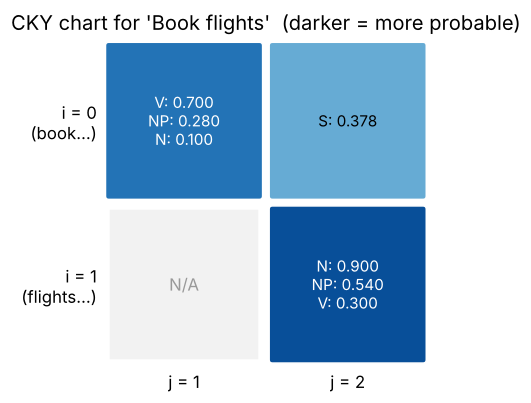

In [10]:
# Visual chart: each cell = one span; colour = best probability in that cell
n = len(words)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (i, j), cell in chart.items():
    best = max(cell.values()) if cell else 0
    ax.add_patch(mpatches.FancyBboxPatch((j - 1 + 0.04, n - 1 - i + 0.04), 0.92, 0.92,
                 boxstyle="round,pad=0.02", fc=plt.cm.Blues(0.25 + 0.7 * best), ec="white"))
    txt = "\n".join(f"{k}: {v:.3f}" for k, v in sorted(cell.items(), key=lambda x: -x[1]))
    ax.text(j - 0.5, n - 0.5 - i, txt, ha="center", va="center", fontsize=10,
            color="white" if best > 0.45 else "black")
for i in range(n):
    for j in range(1, i + 1):
        ax.add_patch(mpatches.Rectangle((j - 1 + 0.04, n - 1 - i + 0.04), 0.92, 0.92, fc="#f2f2f2", ec="white"))
        ax.text(j - 0.5, n - 0.5 - i, "N/A", ha="center", va="center", color="#999")
ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal")
ax.set_xticks([j - 0.5 for j in range(1, n + 1)], [f"j = {j}" for j in range(1, n + 1)])
ax.set_yticks([n - 0.5 - i for i in range(n)], [f"i = {i}\n({words[i]}…)" for i in range(n)])
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("CKY chart for 'Book flights'  (darker = more probable)")
plt.tight_layout(); plt.show()

### 3.2 Back-tracking the best tree
Each cell stores a **back-pointer** saying *how* the best value was obtained. Follow them from `S` in cell $(0, n)$.

In [11]:
def build_tree(back, i, j, A):
    bp = back[(i, j)][A]
    if bp[0] == "word":
        return (A, bp[1])
    if bp[0] == "unary":
        return (A, build_tree(back, i, j, bp[1]))
    _, k, B, Cc = bp
    return (A, build_tree(back, i, k, B), build_tree(back, k, j, Cc))

best_tree = build_tree(back, 0, len(words), "S")
p_best = chart[(0, len(words))]["S"]
print(best_tree)
print(f"\n✅ P(S) = {p_best:.3f}   (slide 15 answer: 0.378)")

('S', ('V', 'book'), ('NP', ('N', 'flights')))

✅ P(S) = 0.378   (slide 15 answer: 0.378)


### 3.3 Resolving ambiguity (slide 17)
What if the parser had read *flights* as a **verb** (`NP → V`)? Compute that alternative tree and compare.

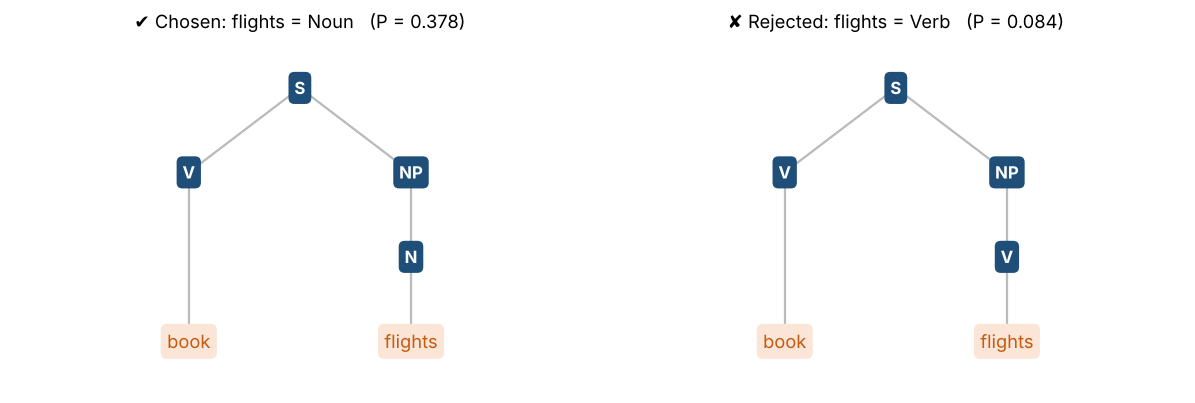

0.378 > 0.084  →  the model is confident 'flights' is a noun here.


In [12]:
p_alt = binary[("S", "V", "NP")] * lexical[("V", "book")] * (unary[("NP", "V")] * lexical[("V", "flights")])
alt_tree = ("S", ("V", "book"), ("NP", ("V", "flights")))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
draw_tree(best_tree, "✔ Chosen: flights = Noun", ax=axes[0], prob=p_best)
draw_tree(alt_tree,  "✘ Rejected: flights = Verb", ax=axes[1], prob=p_alt)
plt.tight_layout(); plt.show()

print(f"{p_best:.3f} > {p_alt:.3f}  →  the model is confident 'flights' is a noun here.")

---
## Part 4 — Transition-Based Dependency Parsing (slides 18–31)
No phrases — only **Head → Dependent** arcs between words.

**Parser state:** Stack σ · Buffer β · Arc set A

| Action | Effect (as defined in the lecture) |
|---|---|
| `SHIFT` | move buffer front → stack top |
| `LEFT-ARC(l)` | buffer front is **head**, stack top is **dependent**; add arc, pop stack |
| `RIGHT-ARC(l)` | stack top is **head**, buffer front is **dependent**; add arc, push dependent onto stack |
| `REDUCE` | pop a stack word that already has its head and no more dependents |
| `ROOT` | final anchor: link ROOT → main verb |

> 💡 **Hint:** in a real parser, a **classifier** (SVM, neural net…) picks the next action from the current state. Here we supply the action sequence from the slides so we can watch the mechanics.

In [13]:
class Parser:
    def __init__(self, sentence):
        self.stack, self.buffer, self.arcs = ["ROOT"], list(sentence), []
        self.history = []
        self._log("INIT")

    def _log(self, action):
        self.history.append({"Step": len(self.history), "Action": action,
                             "Stack σ": "[" + ", ".join(self.stack) + "]",
                             "Buffer β": "[" + ", ".join(self.buffer) + "]",
                             "New arc": ""})

    def shift(self):
        self.stack.append(self.buffer.pop(0)); self._log("SHIFT")

    def left_arc(self, label):
        dep, head = self.stack.pop(), self.buffer[0]
        self.arcs.append((head, label, dep)); self._log(f"LEFT-ARC({label})")
        self.history[-1]["New arc"] = f"{head} →{label}→ {dep}"

    def right_arc(self, label):
        head, dep = self.stack[-1], self.buffer.pop(0)
        self.arcs.append((head, label, dep)); self.stack.append(dep)
        self._log(f"RIGHT-ARC({label})")
        self.history[-1]["New arc"] = f"{head} →{label}→ {dep}"

    def reduce(self):
        self.stack.pop(); self._log("REDUCE")

    def root(self):
        head_word = self.stack.pop()
        self.arcs.append(("ROOT", "root", head_word)); self._log("ROOT-ANCHOR")
        self.history[-1]["New arc"] = f"ROOT →root→ {head_word}"

p = Parser(["He", "eats", "pizza"])
p.shift()               # Step 1
p.left_arc("nsubj")     # Step 2
p.shift()               # Step 3
p.right_arc("obj")      # Step 4
p.reduce()              # Step 5a: pizza has no dependents
p.root()                # Step 5b: anchor eats to ROOT

display(pd.DataFrame(p.history).set_index("Step"))
print("Final arc set A =", p.arcs)

,Action,Stack σ,Buffer β,New arc
Step,,,,
0,INIT,[ROOT],"[He, eats, pizza]",
1,SHIFT,"[ROOT, He]","[eats, pizza]",
2,LEFT-ARC(nsubj),[ROOT],"[eats, pizza]",eats →nsubj→ He
3,SHIFT,"[ROOT, eats]",[pizza],
4,RIGHT-ARC(obj),"[ROOT, eats, pizza]",[],eats →obj→ pizza
5,REDUCE,"[ROOT, eats]",[],
6,ROOT-ANCHOR,[ROOT],[],ROOT →root→ eats


Final arc set A = [('eats', 'nsubj', 'He'), ('eats', 'obj', 'pizza'), ('ROOT', 'root', 'eats')]


### 4.1 Drawing the dependency graph

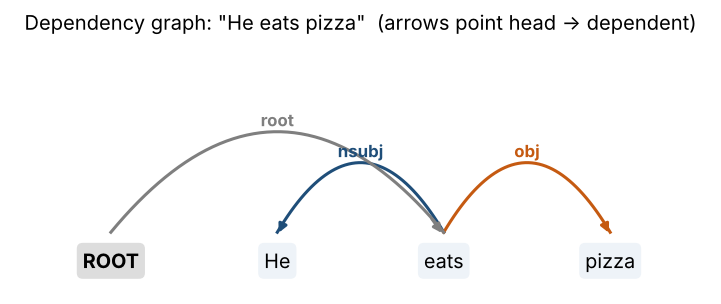

In [14]:
def draw_dependencies(words, arcs, title=""):
    toks = ["ROOT"] + words
    x = {w: i for i, w in enumerate(toks)}
    fig, ax = plt.subplots(figsize=(1.8 * len(toks) + 1, 3))
    for w, i in x.items():
        ax.text(i, 0, w, ha="center", va="top", fontsize=13,
                fontweight="bold" if w == "ROOT" else "normal",
                bbox=dict(boxstyle="round,pad=0.3", fc="#eef3f8" if w != "ROOT" else "#ddd", ec="none"))
    for head, lab, dep in arcs:
        a, b = x[head], x[dep]
        h = 0.35 + 0.28 * abs(b - a)
        mid = (a + b) / 2
        t = np.linspace(0, 1, 50)
        xs = a + (b - a) * t
        ys = 0.15 + 4 * h * t * (1 - t)
        color = {"nsubj": COLORS["nt"], "obj": COLORS["t"], "root": COLORS["gray"]}.get(lab, "k")
        ax.plot(xs, ys, color=color, lw=2)
        ax.annotate("", xy=(b, 0.12), xytext=(xs[-3], ys[-3]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=2))
        ax.text(mid, 0.15 + h + 0.05, lab, ha="center", color=color, fontsize=11, fontweight="bold")
    ax.set_xlim(-0.6, len(toks) - 0.4); ax.set_ylim(-0.4, 1.9); ax.axis("off")
    ax.set_title(title); plt.show()

draw_dependencies(["He", "eats", "pizza"], p.arcs, 'Dependency graph: "He eats pizza"  (arrows point head → dependent)')

### 4.2 Is the graph valid? (slide 22)
Three rules: **single head**, **acyclic**, **connected** (every word reachable from ROOT).

In [15]:
def check_dependency_graph(words, arcs):
    heads = defaultdict(list)
    for h, _, d in arcs:
        heads[d].append(h)
    single_head = all(len(heads[w]) == 1 for w in words)

    # Walk up from each word; if we revisit a node it's a cycle, if we reach ROOT it's connected
    acyclic, connected = True, True
    for w in words:
        seen, cur = set(), w
        while cur != "ROOT":
            if cur in seen or not heads[cur]:
                if cur in seen: acyclic = False
                else: connected = False
                break
            seen.add(cur); cur = heads[cur][0]
    one_root = sum(1 for h, _, _ in arcs if h == "ROOT") == 1
    for name, ok in [("Single head", single_head), ("Acyclic", acyclic),
                     ("Connected", connected), ("Exactly one ROOT arc", one_root)]:
        print(f"  {'✅' if ok else '❌'} {name}")

print("Our parse:"); check_dependency_graph(["He", "eats", "pizza"], p.arcs)
print("\nA broken graph (pizza has two heads, He is floating):")
check_dependency_graph(["He", "eats", "pizza"],
                       [("ROOT", "root", "eats"), ("eats", "obj", "pizza"), ("He", "x", "pizza")])

Our parse:
  ✅ Single head
  ✅ Acyclic
  ✅ Connected
  ✅ Exactly one ROOT arc

A broken graph (pizza has two heads, He is floating):
  ❌ Single head
  ✅ Acyclic
  ❌ Connected
  ✅ Exactly one ROOT arc


### 4.3 Answering "Who eats pizza?" from the arcs (slide 31)
Follow the `obj` arc **backwards** from *pizza* to its head, then find that head's `nsubj`.

In [16]:
head_of_pizza = next(h for h, l, d in p.arcs if d == "pizza" and l == "obj")
subject = next(d for h, l, d in p.arcs if h == head_of_pizza and l == "nsubj")
print(f"pizza ←obj— {head_of_pizza} —nsubj→ {subject}   ⇒  Answer: {subject}")

pizza ←obj— eats —nsubj→ He   ⇒  Answer: He


### 4.4 Speed: O(n) vs O(n³·|R|)
A transition parser makes about **2n** decisions (each word is shifted once and attached once). CKY fills $\frac{n(n+1)}{2}$ cells, each with up to $n$ split points and $|R|$ rules.

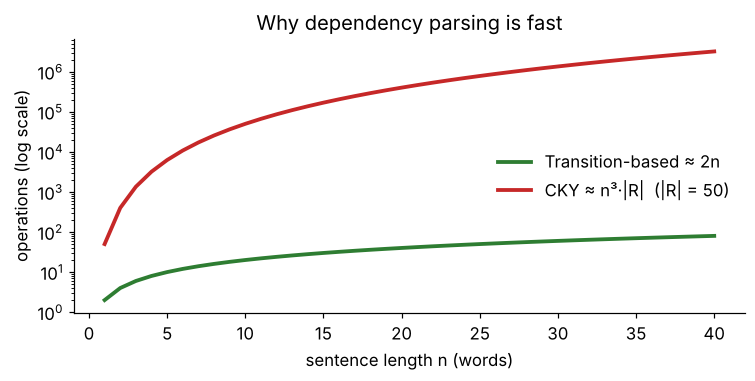

For n = 40: transition ≈ 80 steps vs CKY ≈ 3,200,000 operations


In [17]:
n_vals = np.arange(1, 41)
R_size = 50
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(n_vals, 2 * n_vals, lw=2.5, color=COLORS["ok"], label="Transition-based ≈ 2n")
ax.plot(n_vals, n_vals**3 * R_size, lw=2.5, color=COLORS["bad"], label=f"CKY ≈ n³·|R|  (|R| = {R_size})")
ax.set_yscale("log"); ax.set_xlabel("sentence length n (words)"); ax.set_ylabel("operations (log scale)")
ax.set_title("Why dependency parsing is fast"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"For n = 40: transition ≈ {2*40} steps vs CKY ≈ {40**3*R_size:,} operations")

---
## Part 5 — Classical Statistical Machine Translation (slides 32–45)

### 5.1 The noisy channel
$$\hat{E} = \arg\max_E P(E \mid F) = \arg\max_E \frac{P(F \mid E)\,P(E)}{P(F)} = \arg\max_E \underbrace{P(F \mid E)}_{\text{translation model (fidelity)}} \times \underbrace{P(E)}_{\text{language model (fluency)}}$$

> 💡 **Hint:** $P(F)$ is dropped because the foreign input is fixed — it's the same for every candidate $E$, so it can't change which one wins.

First, the **language model** $P(E)$: a tiny bigram model trained on monolingual English. It should prefer *"the black cat"* over *"cat black the"* (slide 36).

In [18]:
corpus = ("the black cat sleeps . the cat sat on the mat . a black dog runs . "
          "the black cat eats . the white cat sleeps . a cat sat near the black dog .")
tokens = corpus.split()
uni, bi = Counter(tokens), Counter(zip(tokens, tokens[1:]))
vocab = len(uni)

def p_bigram(w1, w2):                    # add-1 (Laplace) smoothing
    return (bi[(w1, w2)] + 1) / (uni[w1] + vocab)

def lm_score(sentence):
    w = ["."] + sentence.split()         # "." acts as sentence-start
    return math.prod(p_bigram(a, b) for a, b in zip(w, w[1:]))

for s in ["the black cat", "the cat black", "cat black the"]:
    print(f"P_LM('{s}') = {lm_score(s):.5f}")

P_LM('the black cat') = 0.00667
P_LM('the cat black') = 0.00105
P_LM('cat black the') = 0.00015


### 5.2 Phrase-based decoding: "Le chat noir" (slides 38–45)
French puts the adjective **after** the noun; English puts it **before**. The decoder multiplies phrase-translation probabilities by a **distortion (reordering) probability**.

In [19]:
phrase_table = {"le": ("the", 0.9), "chat": ("cat", 0.8), "noir": ("black", 0.75)}
distortion   = {"no_reorder": 0.1, "adj_noun_swap": 0.9}

def score_candidate(french_order, reorder):
    # Translate each French word, then multiply in the distortion probability
    p_tr = math.prod(phrase_table[f][1] for f in french_order)
    english = " ".join(phrase_table[f][0] for f in french_order)
    total = p_tr * distortion[reorder]
    terms = " × ".join(str(phrase_table[f][1]) for f in french_order)
    return english, total, f"{terms} × {distortion[reorder]}"

cands = [score_candidate(["le", "chat", "noir"], "no_reorder"),
         score_candidate(["le", "noir", "chat"], "adj_noun_swap")]

df = pd.DataFrame(cands, columns=["English candidate", "Score", "Calculation"])
df["Status"] = np.where(df["Score"] == df["Score"].max(), "Winner ✔", "Rejected ✘")
display(df)

,English candidate,Score,Calculation,Status
0,the cat black,0.054,0.9 × 0.8 × 0.75 × 0.1,Rejected ✘
1,the black cat,0.486,0.9 × 0.75 × 0.8 × 0.9,Winner ✔


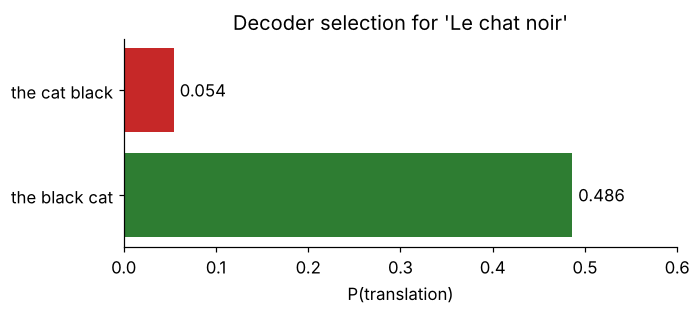

✅ Winner: 'the black cat'  (slide 45: 0.486 vs 0.054)


In [20]:
fig, ax = plt.subplots(figsize=(6.5, 3))
cols = [COLORS["ok"] if s.startswith("Winner") else COLORS["bad"] for s in df["Status"]]
bars = ax.barh(df["English candidate"], df["Score"], color=cols)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set_xlabel("P(translation)"); ax.set_xlim(0, 0.6); ax.invert_yaxis()
ax.set_title("Decoder selection for 'Le chat noir'")
plt.tight_layout(); plt.show()
print(f"✅ Winner: '{df.loc[df.Score.idxmax(), 'English candidate']}'  (slide 45: 0.486 vs 0.054)")

### 5.3 Word alignment picture
The crossing lines are exactly the **reordering** the distortion model rewards.

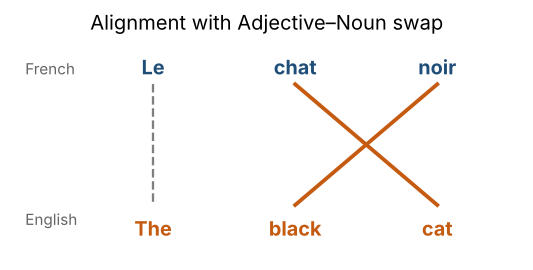

In [21]:
fr, en = ["Le", "chat", "noir"], ["The", "black", "cat"]
align = [(0, 0), (1, 2), (2, 1)]                         # (french idx, english idx)
fig, ax = plt.subplots(figsize=(6, 2.6))
for i, w in enumerate(fr): ax.text(i, 1, w, ha="center", fontsize=13, color=COLORS["nt"], fontweight="bold")
for j, w in enumerate(en): ax.text(j, 0, w, ha="center", va="top", fontsize=13, color=COLORS["t"], fontweight="bold")
for i, j in align:
    crossing = i != j
    ax.plot([i, j], [0.93, 0.08], lw=2.5 if crossing else 1.5,
            color=COLORS["t"] if crossing else COLORS["gray"], ls="-" if crossing else "--")
ax.text(-0.9, 1, "French", fontsize=10, color="#666"); ax.text(-0.9, -0.06, "English", fontsize=10, color="#666")
ax.set_xlim(-1, 2.6); ax.set_ylim(-0.3, 1.25); ax.axis("off")
ax.set_title("Alignment with Adjective–Noun swap")
plt.show()

### 5.4 Putting it together: full noisy-channel search with beam pruning
Now we score **every** ordering of the three English words with $P(F\mid E)\times P(E)$, where the language model from 5.1 supplies fluency. A **beam search** keeps only the top-$K$ partial sentences at each step.

> 💡 **Hint:** with 3 words there are only $3! = 6$ orderings, but with 20 words there are $\approx 2.4\times10^{18}$ — that's why beam search is needed (slide 37).

In [22]:
english_words = ["the", "cat", "black"]                  # translations of le, chat, noir
p_tm = math.prod(v[1] for v in phrase_table.values())   # lexical part is the same for every order

def distortion_p(order):
    if order == ("the", "cat", "black"):  return distortion["no_reorder"]
    if order == ("the", "black", "cat"):  return distortion["adj_noun_swap"]
    return 0.01                                          # (our assumption) any other jumbling is very unlikely

rows = []
for order in itertools.permutations(english_words):
    s = " ".join(order)
    rows.append({"Candidate E": s, "P(F|E)": p_tm * distortion_p(order),
                 "P(E) LM": lm_score(s)})
res = pd.DataFrame(rows)
res["P(F|E)·P(E)"] = res["P(F|E)"] * res["P(E) LM"]
res = res.sort_values("P(F|E)·P(E)", ascending=False).reset_index(drop=True)
display(res.style.format({"P(F|E)": "{:.4f}", "P(E) LM": "{:.5f}", "P(F|E)·P(E)": "{:.2e}"})
           .highlight_max(subset=["P(F|E)·P(E)"], color="#c8e6c9"))

,Candidate E,P(F|E),P(E) LM,P(F|E)·P(E)
0,the black cat,0.4860,0.00667,3.24e-03
1,the cat black,0.0540,0.00105,5.68e-05
2,cat the black,0.0054,0.00053,2.84e-06
3,black cat the,0.0054,0.00044,2.37e-06
4,black the cat,0.0054,0.00028,1.50e-06
5,cat black the,0.0054,0.00015,7.89e-07


In [23]:
def beam_search(words, K=2):
    beam = [((), 1.0)]                                    # (partial sentence, LM score)
    for step in range(len(words)):
        expansions = []
        for partial, sc in beam:
            prev = partial[-1] if partial else "."
            for w in words:
                if w not in partial:
                    expansions.append((partial + (w,), sc * p_bigram(prev, w)))
        beam = sorted(expansions, key=lambda x: -x[1])[:K]
        print(f"step {step+1}: keep {[' '.join(b[0]) for b in beam]}")
    return beam[0]

best, sc = beam_search(english_words, K=2)
print(f"\nBeam search result (K=2): '{' '.join(best)}'")

step 1: keep ['the', 'cat']
step 2: keep ['the black', 'the cat']
step 3: keep ['the black cat', 'the cat black']

Beam search result (K=2): 'the black cat'


---
## Part 6 — BLEU (slides 46–58)
$$\text{BLEU} = BP \times \exp\Big(\sum_{n=1}^{N} w_n \log p_n\Big), \qquad w_n = \tfrac{1}{N}$$

* $p_n$ — **modified (clipped) n-gram precision**
$$p_n = \frac{\sum_{g} \min\big(\text{Count}_{cand}(g),\ \text{Count}_{ref}(g)\big)}{\sum_g \text{Count}_{cand}(g)}$$
* $BP$ — **brevity penalty**: $1$ if $c > r$, else $e^{\,1 - r/c}$

> 💡 **Hint:** we lowercase tokens so that *"The"* and *"the"* count as the same word (that is what the slide 56 calculation does).

In [24]:
def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1))

def modified_precision(cand, ref, n, show=False):
    c, r = ngrams(cand, n), ngrams(ref, n)
    clipped = {g: min(cnt, r[g]) for g, cnt in c.items()}
    if show:
        for g, cnt in c.items():
            print(f"   {' '.join(g):<12} min({cnt}, {r[g]}) = {clipped[g]}")
    return sum(clipped.values()) / max(sum(c.values()), 1)

def brevity_penalty(c, r):
    return 1.0 if c > r else math.exp(1 - r / c)

def bleu(candidate, reference, N=4, show=False):
    cand, ref = candidate.lower().split(), reference.lower().split()
    ps = []
    for n in range(1, N + 1):
        if show: print(f"p{n}:")
        ps.append(modified_precision(cand, ref, n, show))
        if show: print(f"   → p{n} = {ps[-1]:.4f}")
    bp = brevity_penalty(len(cand), len(ref))
    if min(ps) == 0:
        return 0.0, ps, bp
    score = bp * math.exp(sum((1 / N) * math.log(p) for p in ps))
    return score, ps, bp

### 6.1 Why clipping? (slide 50)

In [25]:
cand, ref = "the the the".split(), "the cat is on a mat".split()   # 'the' appears once in the reference
standard = sum(1 for w in cand if w in ref) / len(cand)
modified = modified_precision(cand, ref, 1, show=True)
print(f"Standard precision = {standard:.3f}   (cheated!)")
print(f"Modified precision = {modified:.3f}   ✅ slide answer: 1/3")

   the          min(3, 1) = 1
Standard precision = 1.000   (cheated!)
Modified precision = 0.333   ✅ slide answer: 1/3


### 6.2 Brevity penalty (slide 52)

c = 5, r = 10  →  BP = e^(1 - 10/5) = 0.3679   ✅ slide answer: 0.3679


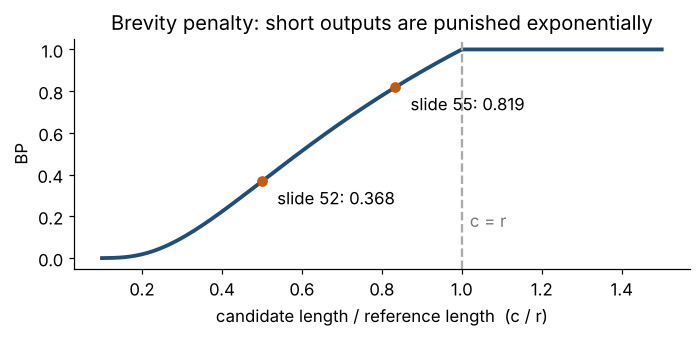

In [26]:
bp = brevity_penalty(5, 10)
print(f"c = 5, r = 10  →  BP = e^(1 - 10/5) = {bp:.4f}   ✅ slide answer: 0.3679")

ratio = np.linspace(0.1, 1.5, 200)
bp_curve = [brevity_penalty(x, 1) for x in ratio]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ratio, bp_curve, lw=2.5, color=COLORS["nt"])
ax.axvline(1, ls="--", color="#aaa"); ax.text(1.02, 0.15, "c = r", color="#777")
for c_r, lbl in [(0.5, "slide 52"), (5/6, "slide 55")]:
    ax.scatter([c_r], [brevity_penalty(c_r, 1)], color=COLORS["t"], zorder=3)
    ax.annotate(f"{lbl}: {brevity_penalty(c_r,1):.3f}", (c_r, brevity_penalty(c_r, 1)),
                xytext=(10, -15), textcoords="offset points")
ax.set_xlabel("candidate length / reference length  (c / r)"); ax.set_ylabel("BP")
ax.set_title("Brevity penalty: short outputs are punished exponentially")
plt.tight_layout(); plt.show()

### 6.3 Complete BLEU-2 worked example (slides 53–58)
* Candidate: **"The cat sat on mat"** (c = 5)
* Reference: **"The cat sat on the mat"** (r = 6)

In [27]:
candidate = "The cat sat on mat"
reference = "The cat sat on the mat"

score, ps, bp = bleu(candidate, reference, N=2, show=True)
print(f"\nBP = e^(1 - 6/5) = {bp:.4f}")
print(f"BLEU-2 = {bp:.4f} × {ps[0]:.2f}^0.5 × {ps[1]:.2f}^0.5 = {score:.4f}")
print(f"✅ slide 58 answer: 0.709  →  {score*100:.1f}%")

p1:
   the          min(1, 2) = 1
   cat          min(1, 1) = 1
   sat          min(1, 1) = 1
   on           min(1, 1) = 1
   mat          min(1, 1) = 1
   → p1 = 1.0000
p2:
   the cat      min(1, 1) = 1
   cat sat      min(1, 1) = 1
   sat on       min(1, 1) = 1
   on mat       min(1, 0) = 0
   → p2 = 0.7500

BP = e^(1 - 6/5) = 0.8187
BLEU-2 = 0.8187 × 1.00^0.5 × 0.75^0.5 = 0.7090
✅ slide 58 answer: 0.709  →  70.9%


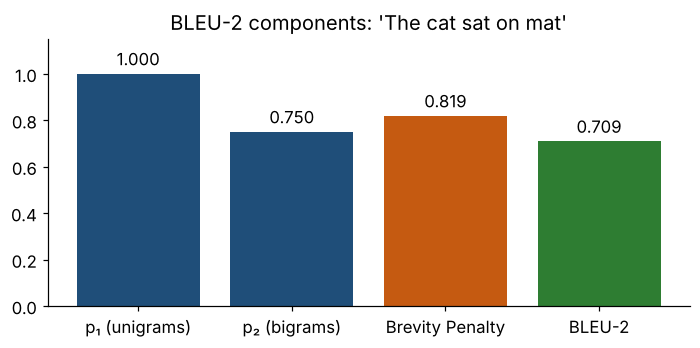

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 3.3))
labels = ["p₁ (unigrams)", "p₂ (bigrams)", "Brevity Penalty", "BLEU-2"]
vals = [ps[0], ps[1], bp, score]
bars = ax.bar(labels, vals, color=[COLORS["nt"], COLORS["nt"], COLORS["t"], COLORS["ok"]])
ax.bar_label(bars, fmt="%.3f", padding=3); ax.set_ylim(0, 1.15)
ax.set_title("BLEU-2 components: 'The cat sat on mat'")
plt.tight_layout(); plt.show()

### 6.4 Compare several candidates
Notice how BLEU rewards matching **word order** (via bigrams) and **length** (via BP).

> 💡 **Hint:** the jumbled candidate has $p_1 = 1$ (all words are correct) but scores badly — word order lives in the higher-order n-grams.

,Candidate,p1,p2,BP,BLEU-2
0,the cat sat on the mat,1.000,1.000,1.000,1.000
1,the cat sat on mat,1.000,0.750,0.819,0.709
2,the cat sat,1.000,1.000,0.368,0.368
3,mat the on sat cat the,1.000,0.000,1.000,0.000
4,the the the the the the,0.333,0.000,1.000,0.000


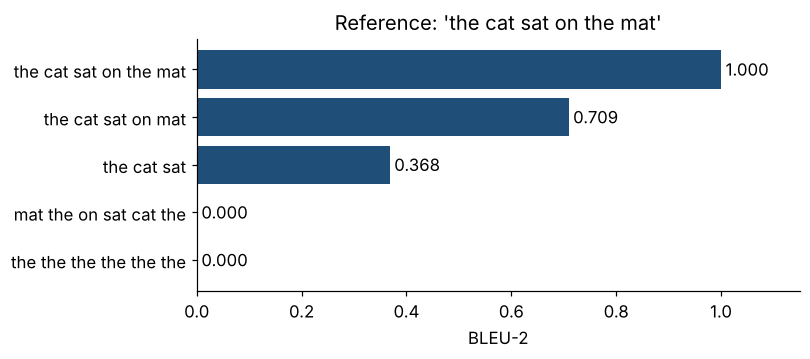

In [29]:
reference = "the cat sat on the mat"
candidates = ["the cat sat on the mat", "the cat sat on mat", "the cat sat",
              "mat the on sat cat the", "the the the the the the"]
rows = []
for c in candidates:
    s, p_, b = bleu(c, reference, N=2)
    rows.append({"Candidate": c, "p1": p_[0], "p2": p_[1], "BP": b, "BLEU-2": s})
bleu_df = pd.DataFrame(rows)
display(bleu_df.style.format({k: "{:.3f}" for k in ["p1", "p2", "BP", "BLEU-2"]})
              .background_gradient(subset=["BLEU-2"], cmap="Greens"))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.barh(bleu_df["Candidate"], bleu_df["BLEU-2"], color=COLORS["nt"])
ax.bar_label(bars, fmt="%.3f", padding=3); ax.invert_yaxis(); ax.set_xlim(0, 1.15)
ax.set_xlabel("BLEU-2"); ax.set_title(f"Reference: '{reference}'")
plt.tight_layout(); plt.show()

---
## Part 7 — Practice Exercises
Try each one before opening the solution. Write your code in the empty cell under each question.

> 💡 **General hint:** every exercise can be solved by re-using a function already defined above (`pcky`, `Parser`, `bleu`, `binarize`…).

### Exercise 1 — CNF
Convert `S → Aux NP V NP PP` into CNF.

<details><summary><b>Show solution</b></summary>

```python
for lhs, rhs in binarize([("S", ("Aux", "NP", "V", "NP", "PP"))]):
    print(lhs, "→", " ".join(rhs))
# S → Aux X1 ; X1 → NP X2 ; X2 → V X3 ; X3 → NP PP
```
</details>

In [30]:
# Your answer here

### Exercise 2 — Changing the PCFG
Change `P(N → book)` to **0.5** and `P(V → book)` to **0.5**. Re-run CKY on "book flights". Does the best tree change? What is the new $P(S)$?

<details><summary><b>Show solution</b></summary>

```python
lexical[("N", "book")], lexical[("V", "book")] = 0.5, 0.5
chart2, back2 = pcky(["book", "flights"], verbose=False)
print(chart2[(0, 2)]["S"])     # 1.0 × 0.5 × 0.54 = 0.27 — same tree, lower confidence
lexical[("N", "book")], lexical[("V", "book")] = 0.1, 0.7   # restore
```
The tree is the same (S needs V in the first cell), but the confidence drops from 0.378 to **0.27**.
</details>

In [31]:
# Your answer here

### Exercise 3 — Dependency parsing by hand
Parse **"She reads books"** with the `Parser` class and draw the graph.

<details><summary><b>Show solution</b></summary>

```python
q = Parser(["She", "reads", "books"])
q.shift(); q.left_arc("nsubj"); q.shift(); q.right_arc("obj"); q.reduce(); q.root()
display(pd.DataFrame(q.history).set_index("Step"))
draw_dependencies(["She", "reads", "books"], q.arcs)
```
Same action sequence as "He eats pizza" — both sentences have the pattern *subject–verb–object*.
</details>

In [32]:
# Your answer here

### Exercise 4 — BLEU by hand
Reference: **"a black cat sleeps on the sofa"** · Candidate: **"a cat sleeps on sofa"**.
Compute $p_1$, $p_2$, $BP$ and BLEU-2 **by hand first**, then check with code.

<details><summary><b>Show solution</b></summary>

* $p_1 = 5/5 = 1$ (all five words appear in the reference)
* Candidate bigrams: *a cat, cat sleeps, sleeps on, on sofa* → only *cat sleeps* and *sleeps on* match → $p_2 = 2/4 = 0.5$
* $c=5, r=7$ → $BP = e^{1-7/5} = e^{-0.4} = 0.670$
* BLEU-2 $= 0.670 \times \sqrt{1 \times 0.5} = $ **0.474**

```python
print(bleu("a cat sleeps on sofa", "a black cat sleeps on the sofa", N=2))
```
</details>

In [33]:
# Your answer here

### Exercise 5 — Think about it
1. Why does SMT need *both* $P(F\mid E)$ and $P(E)$? What would go wrong with only one?
2. Give one reason dependency parsing suits Arabic better than a strict CFG.

<details><summary><b>Show solution</b></summary>

1. With only $P(F\mid E)$ the output is **faithful but broken** ("the cat black"). With only $P(E)$ it is **fluent but unrelated** to the input (any nice English sentence would win). Together they balance fidelity and fluency.
2. Arabic allows flexible word order (VSO and SVO are both common). Dependency arcs link words directly regardless of position, so the same *nsubj/obj* relations are found whichever order is used.
</details>

---
## Part 8 — Mini-Project: ✈️ Flight Booking Assistant (Streamlit app)
We now **apply every concept** to one realistic task: understanding and translating flight-booking requests.

| Step | Lecture concept | What it does for booking |
|---|---|---|
| 1 | PCFG + probabilistic CKY | Is *"book"* a verb or a noun? Where does *"to paris"* attach? |
| 2 | Head rules + arc-eager parser | Turn the tree into `obj`, `obl`, `amod`, `case` arcs |
| 3 | Following arcs | Read off **action, object, origin, destination, date** |
| 4 | Phrase-based SMT | Translate *"Réserver un vol direct pour Paris"* |
| 5 | BLEU | Score the translation against a human reference |

The engine lives in **`booking_nlp.py`** (pure Python, readable), the interface in **`app.py`**. Keep both files next to this notebook.

> 💡 **Hint:** the notebook and the app share the same code, so anything you test here is exactly what the app shows.

In [34]:
import importlib, sys, os
sys.path.insert(0, os.getcwd())
import booking_nlp as nlp
importlib.reload(nlp)

g = nlp.make_grammar(p_v_book=0.7, p_n_book=0.1)
request = "book the cheapest flight from beirut to dubai on monday"
res = nlp.parse(request, g)
print(f"{len(res['parses'])} parses found. Top 3:")
for p_, t in res["parses"][:3]:
    print(f"  P = {p_:.2e}   {nlp.bracket(t)}")

8 parses found. Top 3:
  P = 1.13e-12   [S [VP [VP [VP [VP [V book] [NP [Det the] [Nom [Adj cheapest] [Nom [N flight]]]]] [PP [P from] [NP [PropN beirut]]]] [PP [P to] [NP [PropN dubai]]]] [PP [P on] [NP [Nom [N monday]]]]]]
  P = 8.10e-13   [S [VP [VP [VP [V book] [NP [Det the] [Nom [Adj cheapest] [Nom [N flight]]]]] [PP [P from] [NP [PropN beirut]]]] [PP [P to] [NP [NP [PropN dubai]] [PP [P on] [NP [Nom [N monday]]]]]]]]
  P = 8.10e-13   [S [VP [VP [VP [V book] [NP [Det the] [Nom [Adj cheapest] [Nom [N flight]]]]] [PP [P from] [NP [NP [PropN beirut]] [PP [P to] [NP [PropN dubai]]]]]] [PP [P on] [NP [Nom [N monday]]]]]]


### 8.1 From tree → dependencies → booking
> 💡 **Hint:** look at the `case` arcs — the preposition tells us the *role* of the city (`from` → origin, `to` → destination).

,Action,Stack,Buffer
0,INIT,[ROOT],"[book, the, cheapest, flight, from, beirut, to..."
1,RIGHT-ARC(root),"[ROOT, book]","[the, cheapest, flight, from, beirut, to, duba..."
2,SHIFT,"[ROOT, book, the]","[cheapest, flight, from, beirut, to, dubai, on..."
3,SHIFT,"[ROOT, book, the, cheapest]","[flight, from, beirut, to, dubai, on, monday]"
4,LEFT-ARC(amod),"[ROOT, book, the]","[flight, from, beirut, to, dubai, on, monday]"
5,LEFT-ARC(det),"[ROOT, book]","[flight, from, beirut, to, dubai, on, monday]"
6,RIGHT-ARC(obj),"[ROOT, book, flight]","[from, beirut, to, dubai, on, monday]"
7,SHIFT,"[ROOT, book, flight, from]","[beirut, to, dubai, on, monday]"


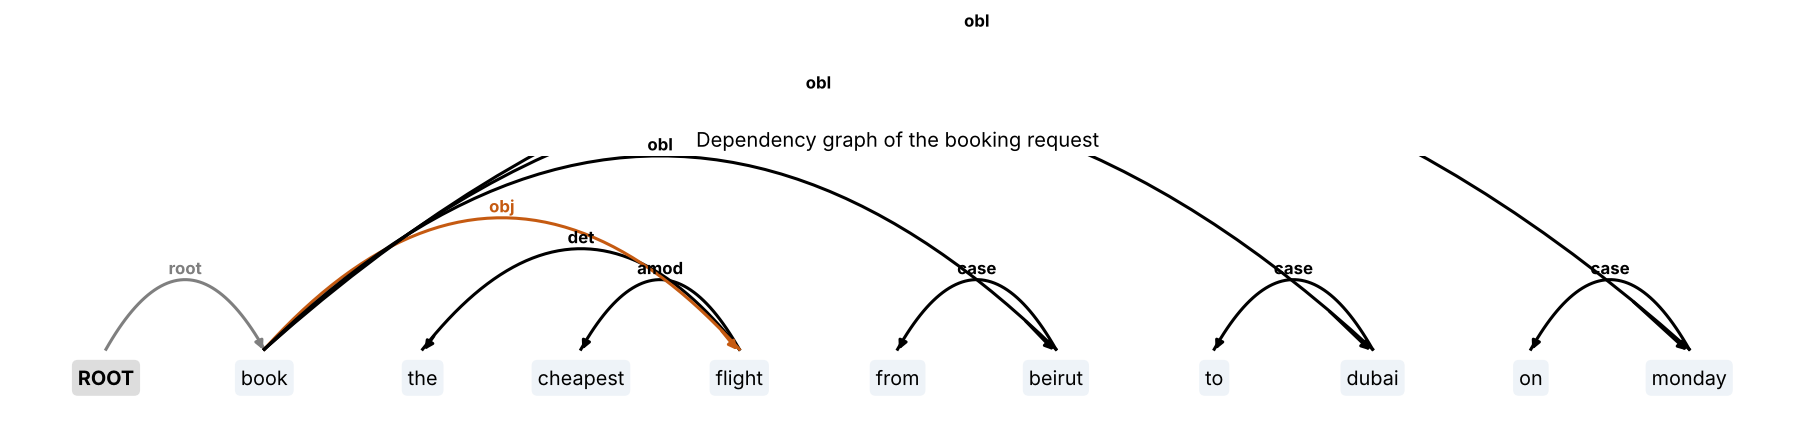

,value
Action,book
Object,flight
Preferences,[cheapest]
Origin,beirut
Destination,dubai
Date / time,monday
Is a command,True


In [35]:
best_tree = res["parses"][0][1]
heads, labels = nlp.tree_to_dependencies(best_tree)
states = nlp.arc_eager(res["words"], heads, labels)
toks = ["ROOT"] + res["words"]

display(pd.DataFrame([{"Action": s["action"],
                       "Stack": [toks[i] for i in s["stack"]],
                       "Buffer": [toks[i] for i in s["buffer"]]} for s in states]).head(8))

arcs = states[-1]["arcs"]
draw_dependencies(res["words"], [(toks[h], l, toks[d]) for h, l, d in arcs], "Dependency graph of the booking request")

tags = []
def collect(t):
    if nlp.is_pre(t): tags.append(t[0])
    else: [collect(c) for c in t[1:]]
collect(best_tree)
slots = nlp.extract_slots(res["words"], tags, arcs)
display(pd.Series(slots, name="value").to_frame())

### 8.2 Translate and evaluate

In [36]:
fr = "Réserver un vol direct pour Paris"
out = nlp.smt_decode(fr, p_swap=0.9, lm_weight=1.0, beam=5)
display(pd.DataFrame(out["candidates"]).head(5).style.format(precision=2))

b = nlp.bleu(out["candidates"][0]["english"], ["book a direct flight to paris"], N=2)
print(f"Best translation: {out['candidates'][0]['english']!r}   BLEU-2 = {b['bleu']:.3f}")

,english,score,log P(F|E),log d,log P(E)
0,book a direct flight to paris,-9.85,-1.59,-0.11,-8.15
1,reserve a direct flight to paris,-12.91,-2.00,-0.11,-10.81
2,book a direct flight for paris,-16.66,-1.59,-0.11,-14.96
3,book a flight direct to paris,-18.96,-1.59,-2.30,-15.07
4,book a flight direct for paris,-21.51,-1.59,-2.30,-17.62


Best translation: 'book a direct flight to paris'   BLEU-2 = 1.000


### 8.3 Launch the interactive app
**Option A — your own computer (recommended).** Open a terminal in this folder and run:
```bash
pip install -r requirements.txt
streamlit run app.py
```
Your browser opens at `http://localhost:8501`.

**Option B — from inside Jupyter.** Uncomment and run the cell below; it starts the app in the background. Then open `http://localhost:8501`.

**Option C — Google Colab.** Upload `app.py` and `booking_nlp.py`, then run:
```python
!pip -q install streamlit
!streamlit run app.py &>/content/log.txt &
!npx --yes localtunnel --port 8501      # open the printed URL; the password is your Colab IP: !curl ipv4.icanhazip.com
```

**What to try in the app**
1. Tab ①: drag **P(V → book)** to the minimum and **P(N → book)** to the maximum — *"book flights"* becomes a noun phrase.
2. Tab ①: move the **PP attachment** slider — *"to paris"* switches between modifying the verb and the flight.
3. Tab ②: step through the transitions with the slider and watch Stack / Buffer / Arcs change.
4. Tab ③: set **λ = 0** and **reorder = 0.1** — see the translation break, like *"The cat black"*.
5. Tab ④: try the candidate *"the the the the"* to see clipping in action.

In [37]:
# import subprocess
# app = subprocess.Popen(["streamlit", "run", "app.py", "--server.headless", "true"])
# print("App running at http://localhost:8501   (stop it with: app.terminate())")

---
## Summary
| Concept | Key idea | Cost |
|---|---|---|
| CFG | Hierarchy of phrases from rewrite rules | — |
| CKY | Bottom-up dynamic programming over spans (needs CNF) | $O(n^3\,\lvert R\rvert)$ |
| Dependency parsing | Head → dependent arcs, built with Stack/Buffer actions | $O(n)$ |
| SMT | $\arg\max_E P(F\mid E)\,P(E)$ + beam search decoder | heuristic |
| BLEU | Clipped n-gram precision × brevity penalty | automatic |

**Next:** these separate pipelines were replaced by end-to-end **neural Seq2Seq** models (slide 60).